In [1]:
import os, glob, pickle
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os, glob, pickle
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans', 'sans-serif']

# Make mathtext look like Arial
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Arial'
mpl.rcParams['mathtext.it'] = 'Arial:italic'
mpl.rcParams['mathtext.bf'] = 'Arial:bold' 

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
# --- Settings ---
# --- 1) .pkl directory ---
PKL_DIR = r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\manipulation\pre_post"

# --- 2) Helper to load ca1_complete_df from each .pkl ---
def load_ca1_df(pkl_path):
    with open(pkl_path, "rb") as f:
        obj = pickle.load(f)
    if isinstance(obj, pd.DataFrame):
        df = obj
    elif isinstance(obj, dict):
        if "ca1_complete_df" in obj:
            df = obj["ca1_complete_df"]
        else:
            df = next((v for v in obj.values() if isinstance(v, pd.DataFrame)), None)
            if df is None:
                raise ValueError(f"No DataFrame found in {os.path.basename(pkl_path)}")
    else:
        raise ValueError(f"Unsupported PKL content in {os.path.basename(pkl_path)}")

    df = df.copy()
    df["animal_day"] = os.path.splitext(os.path.basename(pkl_path))[0]
    return df

# --- 3) Load all .pkl files ---
all_pkls = sorted(glob.glob(os.path.join(PKL_DIR, "*.pkl")))
dfs = []
for p in all_pkls:
    try:
        dfs.append(load_ca1_df(p))
        print(f"Loaded: {os.path.basename(p)}")
    except Exception as e:
        print(f"[skip] {os.path.basename(p)} -> {e}")

if not dfs:
    raise RuntimeError("No usable PKL files loaded.")

# --- 4) Combine all into one pooled dataframe ---
full_df = pd.concat(dfs, ignore_index=True)

Loaded: PPP20_day4.pkl
Loaded: PPP20_day5.pkl
Loaded: PPP21_day4.pkl
Loaded: PPP21_day5.pkl
Loaded: PPP23_day7.pkl
Loaded: PPP23_day8.pkl
Loaded: PPP4_day11.pkl
Loaded: PPP7_day10.pkl
Loaded: PPP8_day8.pkl


Epoch counts in plot_df:
sleep_epoch
midsleep    13841
presleep    12646
Name: count, dtype: int64
Per-file entries per epoch:
sleep_epoch
midsleep    9
presleep    9
Name: count, dtype: int64


C:\Users\Cornell\AppData\Local\Temp\ipykernel_62368\2973721433.py:193: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Cornell\AppData\Local\Temp\ipykernel_62368\2973721433.py:212: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


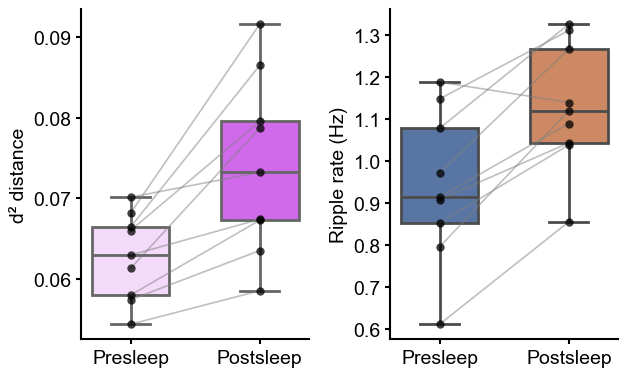

Saved: D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\individual_fig_main\fig2A_S2B_pre_vs_postsleep_perfile_paired.svg


In [41]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl

# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
# ------------------------------
# 1) File-aware epoch selection
# ------------------------------
tmp = full_df.copy()

# normalize naming
tmp["sleep_epoch"] = tmp["sleep_epoch"].astype(str).str.lower()

keep_rows = []

for file_id, g in tmp.groupby("animal_day"):
    # NREM only
    g_nrem = g[g["state"].astype(str).str.upper() == "NREM"]
    if g_nrem.empty:
        continue

    has_midsleep = (g_nrem["sleep_epoch"] == "midsleep").any()
    has_postsleep = (g_nrem["sleep_epoch"] == "postsleep").any()

    if has_midsleep:
        chosen_epochs = ["presleep", "midsleep"]
    elif has_postsleep:
        # fallback: use presleep + postsleep
        chosen_epochs = ["presleep", "postsleep"]
    else:
        # worst case: only presleep
        chosen_epochs = ["presleep"]

    selected = g_nrem[g_nrem["sleep_epoch"].isin(chosen_epochs)]
    keep_rows.append(selected)

plot_df = pd.concat(keep_rows, ignore_index=True)

print("Epoch counts in plot_df:")
print(plot_df["sleep_epoch"].value_counts())

# ------------------------------------------
# 2) Per-file (animal_day) mean per epoch
# ------------------------------------------
summary_df = (
    plot_df
    .groupby(["animal_day", "sleep_epoch"], as_index=False)[["d2", "ripple_rate_30s"]]
    .mean()
)

print("Per-file entries per epoch:")
print(summary_df["sleep_epoch"].value_counts())

# ------------------------------
# 3) Boxplots (per-file means)
# ------------------------------
order = ["presleep", "midsleep", "postsleep"]  # some files won’t have all 3
palette = {
    "presleep":  "#4c72b0",
    "midsleep":  "#dd8452",
    "postsleep": "#55a868",
}

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ------------------------
# 1) File-aware epoch selection
# ------------------------
tmp = full_df.copy()
tmp["sleep_epoch"] = tmp["sleep_epoch"].astype(str).str.lower()

keep_rows = []

for file_id, g in tmp.groupby("animal_day"):

    g_nrem = g[g["state"].astype(str).str.upper() == "NREM"]
    if g_nrem.empty:
        continue

    has_midsleep = (g_nrem["sleep_epoch"] == "midsleep").any()
    has_postsleep = (g_nrem["sleep_epoch"] == "postsleep").any()

    # Main rule:
    # Prefer: presleep + midsleep
    # Otherwise fallback: presleep + postsleep
    if has_midsleep:
        chosen = ["presleep", "midsleep"]
    elif has_postsleep:
        chosen = ["presleep", "postsleep"]
    else:
        chosen = ["presleep"]

    keep_rows.append(g_nrem[g_nrem["sleep_epoch"].isin(chosen)])

plot_df = pd.concat(keep_rows, ignore_index=True)

# ------------------------
# 2) Relabel epochs → Pre vs Postsleep
# ------------------------
def relabel(ep):
    if ep == "presleep":
        return "Presleep"
    else:
        return "Postsleep"   # midsleep or postsleep fallback

plot_df["epoch2"] = plot_df["sleep_epoch"].map(relabel)

# ------------------------
# 3) Per-file mean per epoch
# ------------------------
summary_df = (
    plot_df.groupby(["animal_day", "epoch2"], as_index=False)[["d2", "ripple_rate_30s"]]
            .mean()
)

# ------------------------
# 4) Helper for paired lines
# ------------------------
def draw_paired_lines(ax, df_pair, y_col, order):
    """
    df_pair: per-file summary
    y_col: "d2" or "ripple_rate_30s"
    order: ["Pre", "Postsleep"]
    """
    pivot = df_pair.pivot(index="animal_day", columns="epoch2", values=y_col)
    pivot = pivot.dropna()   # keep only paired files

    for file_id, row in pivot.iterrows():
        ax.plot(
            [order[0], order[1]],
            [row[order[0]], row[order[1]]],
            color="gray", alpha=0.5, linewidth=1.2,
            zorder=2
        )

# ------------------------
# 5) Plot (two panels): d² and ripple rate
# ------------------------
order = ["Presleep", "Postsleep"]
palette = {"Presleep": "#f6d5ffff", "Postsleep": "#dd55ffff"}

fig, axes = plt.subplots(1, 2, figsize=(6.5, 4))

# -------- D² panel --------
ax = axes[0]


sns.boxplot(
    data=summary_df, x="epoch2", y="d2",
    order=order, palette=palette,
    showfliers=False, width=0.6, linewidth=2, ax=ax, zorder=2
)

sns.stripplot(
    data=summary_df, x="epoch2", y="d2",
    order=order, color="k", jitter=False,
    alpha=0.75, size=6, ax=ax, zorder=3
)
draw_paired_lines(ax, summary_df, y_col="d2", order=order)
ax.set_xlabel("")
ax.set_ylabel("d² distance")
palette={"Presleep": "#4c72b0", "Postsleep": "#dd8452"}

# -------- Ripple rate panel --------
ax = axes[1]

sns.boxplot(
    data=summary_df, x="epoch2", y="ripple_rate_30s",
    order=order, palette=palette,
    showfliers=False, width=0.6, linewidth=2, ax=ax, zorder=2
)

sns.stripplot(
    data=summary_df, x="epoch2", y="ripple_rate_30s",
    order=order, color="k", jitter=False,
    alpha=0.75, size=6, ax=ax, zorder=3
)

ax.set_xlabel("")
ax.set_ylabel("Ripple rate (Hz)")
draw_paired_lines(ax, summary_df, y_col="ripple_rate_30s", order=order)


# Aesthetics
for ax in axes:
    sns.despine(ax=ax)
    ax.grid(False)
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)

plt.tight_layout()

save_path = r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\individual_fig_main\fig2A_S2B_pre_vs_postsleep_perfile_paired.svg"
plt.savefig(save_path, dpi=300)
plt.show()

print("Saved:", save_path)

In [56]:
import statsmodels.formula.api as smf

# -----------------------------------------
# 3b) Paired linear mixed models (per file)
# -----------------------------------------

order = ["Presleep", "Postsleep"]  # already defined above, but restate for clarity
# make sure animal_day is string
summary_df = summary_df.copy()
summary_df["animal_day"] = summary_df["animal_day"].astype(str)

# extract animal from "PPP20_day4" -> "PPP20"
summary_df["animal"] = summary_df["animal_day"].str.split("_", n=1, expand=True)[0]

# (optional) check
print(summary_df[["animal_day", "animal"]].drop_duplicates().head(10))
print("n animals:", summary_df["animal"].nunique())
print("n animal_day:", summary_df["animal_day"].nunique())

import pandas as pd
import statsmodels.formula.api as smf
def p_to_stars(p):
    p = float(p)
    if not np.isfinite(p):
        return ""
    if p < 1e-4:
        return "****"
    if p < 1e-3:
        return "***"
    if p < 1e-2:
        return "**"
    if p < 5e-2:
        return "*"
    return "ns"
def run_lmm(summary_df, y_col, order=("Presleep", "Postsleep"),
            animal_col="animal", day_col="animal_day", epoch_col="epoch2",
            reml=False):
    """
    Paired LMM with animal as grouping factor + animal_day as within-animal variance component:

        y ~ C(epoch2)  +  (1|animal)  +  (1|animal_day)

    Pairing: keep only animal_day that have BOTH epochs.
    """
    # --- keep only paired animal_day (both epochs) ---
    pivot = summary_df.pivot(index=day_col, columns=epoch_col, values=y_col)
    paired_ids = pivot.dropna().index
    df = summary_df[summary_df[day_col].isin(paired_ids)].copy()

    # --- categorical ordering ---
    df[epoch_col] = pd.Categorical(df[epoch_col], categories=order, ordered=True)

    # --- MixedLM: random intercept by animal; variance component for animal_day ---
    # animal_day VC ensures pairing / day-to-day intercepts beyond animal baseline
    vc = {day_col: f"0 + C({day_col})"}   # random intercept per animal_day

    model = smf.mixedlm(
        f"{y_col} ~ C({epoch_col})",
        data=df,
        groups=df[animal_col],           # (1|animal)
        vc_formula=vc                    # + (1|animal_day)
    )
    res = model.fit(reml=reml)

    print(f"\n=== LMM for {y_col} : (1|animal) + (1|animal_day) ===")
    print(res.summary())

    # Contrast term: Postsleep vs Presleep (Presleep is reference)
    coef_name = f"C({epoch_col})[T.{order[1]}]"  # order[1] is "Postsleep"
    stars = p_to_stars(res.pvalues[coef_name])
    if coef_name in res.params.index:
        beta = float(res.params[coef_name])
        pval = float(res.pvalues[coef_name])
        print(f"\nEffect ({order[1]} – {order[0]}) on {y_col}:")
        print(f"  Δ = {beta:.4g}")
        print(f"  ({stars})")
        print(f"  p = {pval:.3g}")
    else:
        print("Could not find contrast term in model parameters:", coef_name)

    return res

order = ("Presleep", "Postsleep")
res_d2   = run_lmm(summary_df, "d2",              order=order, animal_col="animal", day_col="animal_day")
res_ripp = run_lmm(summary_df, "ripple_rate_30s", order=order, animal_col="animal", day_col="animal_day")

    animal_day animal
0   PPP20_day4  PPP20
2   PPP20_day5  PPP20
4   PPP21_day4  PPP21
6   PPP21_day5  PPP21
8   PPP23_day7  PPP23
10  PPP23_day8  PPP23
12  PPP4_day11   PPP4
14  PPP7_day10   PPP7
16   PPP8_day8   PPP8
n animals: 6
n animal_day: 9

=== LMM for d2 : (1|animal) + (1|animal_day) ===
             Mixed Linear Model Regression Results
Model:                 MixedLM    Dependent Variable:    d2     
No. Observations:      18         Method:                ML     
No. Groups:            6          Scale:                 0.0000 
Min. group size:       2          Log-Likelihood:        63.1825
Max. group size:       4          Converged:             Yes    
Mean group size:       3.0                                      
----------------------------------------------------------------
                       Coef. Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------------
Intercept              0.063    0.003 23.170 0.000  0.057  0.068


c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Matched ripple rate distribution

Counts by epoch2 (raw NREM windows):
epoch2
Postsleep    13841
Presleep     12646
Name: count, dtype: int64
Matched files: 9
             n_pre       n_post
count     9.000000     9.000000
mean    948.444444   948.444444
std     387.823772   387.823772
min     428.000000   428.000000
25%     509.000000   509.000000
50%    1010.000000  1010.000000
75%    1183.000000  1183.000000
max    1444.000000  1444.000000


C:\Users\Cornell\AppData\Local\Temp\ipykernel_62368\1016173726.py:185: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


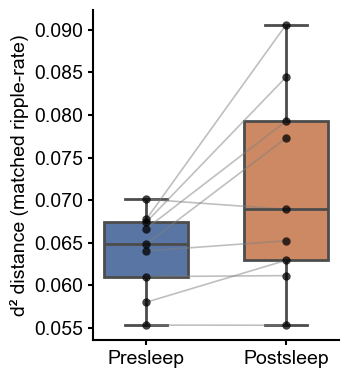

Ripple mean differences after matching (post - pre):
count    9.000000
mean    -0.000111
std      0.004665
min     -0.007243
25%     -0.005102
50%      0.001782
75%      0.003531
max      0.005035
Name: rip_diff, dtype: float64


In [43]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ------------------------
# CONFIG
# ------------------------
RNG_SEED = 0
N_BINS = 12                 # bins for matching ripple rate distribution
MIN_PER_BIN = 3             # require at least this many per bin per epoch to match
STATE_KEEP = "NREM"

rng = np.random.default_rng(RNG_SEED)

# ------------------------
# 1) NREM only + file-aware epoch selection
# ------------------------
tmp = full_df.copy()
tmp["sleep_epoch"] = tmp["sleep_epoch"].astype(str).str.lower()
tmp["state"] = tmp["state"].astype(str).str.upper()

keep_rows = []
for file_id, g in tmp.groupby("animal_day"):
    g_nrem = g[g["state"] == STATE_KEEP].copy()
    if g_nrem.empty:
        continue

    has_midsleep = (g_nrem["sleep_epoch"] == "midsleep").any()
    has_postsleep = (g_nrem["sleep_epoch"] == "postsleep").any()

    if has_midsleep:
        chosen = ["presleep", "midsleep"]
    elif has_postsleep:
        chosen = ["presleep", "postsleep"]
    else:
        chosen = ["presleep"]

    keep_rows.append(g_nrem[g_nrem["sleep_epoch"].isin(chosen)])

plot_df = pd.concat(keep_rows, ignore_index=True)

# relabel to 2 epochs: Presleep vs Postsleep (midsleep OR postsleep becomes Postsleep)
plot_df["epoch2"] = np.where(plot_df["sleep_epoch"] == "presleep", "Presleep", "Postsleep")

# Keep only rows with required columns
plot_df = plot_df.dropna(subset=["d2", "ripple_rate_30s", "animal_day", "epoch2"]).copy()

print("Counts by epoch2 (raw NREM windows):")
print(plot_df["epoch2"].value_counts())

# ------------------------
# 2) Helper: match ripple-rate distribution within each file
#    (bin-matched subsampling)
# ------------------------
def match_by_ripple_bins(df_file, ripple_col="ripple_rate_30s", epoch_col="epoch2",
                         d2_col="d2", n_bins=10, min_per_bin=3, rng=None):
    """
    Returns matched subsets for Presleep and Postsleep with the SAME per-bin counts,
    plus per-file means of ripple and d2 after matching.

    Strategy:
      - define bins using pooled ripple values (both epochs together) within this file
      - compute counts per bin per epoch
      - take k = min(count_pre, count_post) per bin
      - sample k from each epoch/bin (without replacement)
    """
    if rng is None:
        rng = np.random.default_rng(0)

    df_file = df_file.copy()
    if df_file[epoch_col].nunique() < 2:
        return None

    pre = df_file[df_file[epoch_col] == "Presleep"].copy()
    post = df_file[df_file[epoch_col] == "Postsleep"].copy()
    if len(pre) == 0 or len(post) == 0:
        return None

    # bins from pooled ripple distribution within file
    x_all = df_file[ripple_col].to_numpy(float)
    # Guard against a ripple distribution too discrete or constant to bin
    if np.nanmin(x_all) == np.nanmax(x_all):
        # ripple identical everywhere: just downsample to min(n_pre, n_post)
        n = min(len(pre), len(post))
        pre_s = pre.sample(n=n, replace=False, random_state=int(rng.integers(1e9)))
        post_s = post.sample(n=n, replace=False, random_state=int(rng.integers(1e9)))
        return pre_s, post_s

    # Use quantile-based bins for robust matching
    try:
        df_file["_bin"] = pd.qcut(df_file[ripple_col], q=n_bins, duplicates="drop")
    except Exception:
        # fallback: equal-width
        edges = np.linspace(np.nanmin(x_all), np.nanmax(x_all), n_bins + 1)
        df_file["_bin"] = pd.cut(df_file[ripple_col], bins=edges, include_lowest=True)

    pre = df_file[df_file[epoch_col] == "Presleep"].copy()
    post = df_file[df_file[epoch_col] == "Postsleep"].copy()

    # counts per bin
    c_pre = pre["_bin"].value_counts()
    c_post = post["_bin"].value_counts()

    bins = sorted(set(c_pre.index).intersection(set(c_post.index)))
    if len(bins) == 0:
        return None

    keep_pre = []
    keep_post = []
    for b in bins:
        n_pre = int(c_pre.get(b, 0))
        n_post = int(c_post.get(b, 0))
        k = min(n_pre, n_post)

        if k < min_per_bin:
            continue

        pre_b = pre[pre["_bin"] == b]
        post_b = post[post["_bin"] == b]

        # sample k from each
        pre_s = pre_b.sample(n=k, replace=False, random_state=int(rng.integers(1e9)))
        post_s = post_b.sample(n=k, replace=False, random_state=int(rng.integers(1e9)))
        keep_pre.append(pre_s)
        keep_post.append(post_s)

    if len(keep_pre) == 0 or len(keep_post) == 0:
        return None

    pre_m = pd.concat(keep_pre, ignore_index=True)
    post_m = pd.concat(keep_post, ignore_index=True)
    return pre_m, post_m

# ------------------------
# 3) Run matching per file, build per-file summary
# ------------------------
rows = []

for file_id, g in plot_df.groupby("animal_day"):
    matched = match_by_ripple_bins(
        g,
        ripple_col="ripple_rate_30s",
        epoch_col="epoch2",
        d2_col="d2",
        n_bins=N_BINS,
        min_per_bin=MIN_PER_BIN,
        rng=rng
    )
    if matched is None:
        continue

    pre_m, post_m = matched

    # ripple means after matching
    rows.append({
        "animal_day": file_id,
        "d2_pre": float(pre_m["d2"].mean()),
        "d2_post": float(post_m["d2"].mean()),
        "rip_pre": float(pre_m["ripple_rate_30s"].mean()),
        "rip_post": float(post_m["ripple_rate_30s"].mean()),
        "n_pre": int(len(pre_m)),
        "n_post": int(len(post_m)),
    })

matched_df = pd.DataFrame(rows)
print("Matched files:", matched_df["animal_day"].nunique())
print(matched_df[["n_pre","n_post"]].describe())

# Long format for plotting
plot_summary = pd.concat([
    matched_df[["animal_day"]].assign(epoch2="Presleep", d2=matched_df["d2_pre"]),
    matched_df[["animal_day"]].assign(epoch2="Postsleep", d2=matched_df["d2_post"]),
], ignore_index=True)

# ------------------------
# 4) Plot paired box + points + lines
# ------------------------
order = ["Presleep", "Postsleep"]
palette = {"Presleep": "#4c72b0", "Postsleep": "#dd8452"}

fig, ax = plt.subplots(1, 1, figsize=(3.6, 4.0))

sns.boxplot(
    data=plot_summary, x="epoch2", y="d2",
    order=order, palette=palette,
    showfliers=False, width=0.6, linewidth=2, ax=ax, zorder=2
)

sns.stripplot(
    data=plot_summary, x="epoch2", y="d2",
    order=order, color="k", jitter=False,
    alpha=0.75, size=6, ax=ax, zorder=3
)

# paired lines
pivot = plot_summary.pivot(index="animal_day", columns="epoch2", values="d2").dropna()
for fid, row in pivot.iterrows():
    ax.plot([0, 1], [row["Presleep"], row["Postsleep"]],
            color="gray", alpha=0.5, linewidth=1.2, zorder=2)

ax.set_xlabel("")
ax.set_ylabel("d² distance (matched ripple-rate)")
ax.grid(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

plt.tight_layout()
save_path = r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\individual_fig_supp\fig3S_A_d2_pre_post_matched_ripple.svg"
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

# Optional: inspect ripple matching quality
matched_df["rip_diff"] = matched_df["rip_post"] - matched_df["rip_pre"]
print("Ripple mean differences after matching (post - pre):")
print(matched_df["rip_diff"].describe())

In [57]:
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon, ttest_rel, shapiro

# matched_df must contain: animal_day, d2_pre, d2_post
# (from the ripple-matched per-file sampling)

paired = matched_df.dropna(subset=["d2_pre", "d2_post"]).copy()

# paired difference: post - pre
paired["d2_diff"] = paired["d2_post"] - paired["d2_pre"]

n = len(paired)
mean_diff = paired["d2_diff"].mean()
sem_diff  = paired["d2_diff"].std(ddof=1) / np.sqrt(n) if n > 1 else np.nan

print(f"Paired animal_day N = {n}")
print(f"Mean(Post-Pre) = {mean_diff:.6g} ± {sem_diff:.6g} (SEM)")

# --- Wilcoxon signed-rank (robust default) ---
# Guard against wilcoxon raising when many differences are exactly zero.
try:
    w_stat, p_w = wilcoxon(paired["d2_post"], paired["d2_pre"], alternative="two-sided", zero_method="wilcox")
except Exception as e:
    w_stat, p_w = np.nan, np.nan
    print("[WARN] Wilcoxon failed:", e)

print(f"Wilcoxon signed-rank p = {p_w:.3g}")

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

# 1. Prepare the Data
# We assume 'matched_df' has 'animal_day', 'd2_pre', 'd2_post'
df_use = matched_df.dropna(subset=["d2_pre", "d2_post"]).copy()

# Try to extract 'Animal' from 'animal_day' if a separate column doesn't exist
# Assuming format like "Mouse1_Day1" or similar. Adjust split logic if needed.
if "animal" not in df_use.columns:
    # Example: splits "AG1_Day1" -> "AG1"
    df_use["animal"] = df_use["animal_day"].apply(lambda x: str(x).split('_')[0])

# 2. Convert to Long Format (Melt)
long_df = df_use.melt(
    id_vars=["animal", "animal_day"], 
    value_vars=["d2_pre", "d2_post"], 
    var_name="Condition", 
    value_name="d2_value"
)

# 3. Fit Linear Mixed Model
# Fixed Effect: Condition (Pre vs Post)
# Random Effect: Animal (Intercept) - accounts for baseline differences between mice
# We treat 'Condition' as categorical (C). 'd2_pre' becomes the reference level automatically if alphabetical, 
# or we can force it.
print(f"Fitting LMM on {len(long_df)} observations from {long_df['animal'].nunique()} animals...")

model = smf.mixedlm(
    "d2_value ~ Condition", 
    data=long_df, 
    groups=long_df["animal"]
)

result = model.fit()

# 4. Print Results
print(result.summary())

# Extract p-value for the condition
p_val = result.pvalues["Condition[T.d2_pre]"] # Or d2_post depending on reference
coef = result.params["Condition[T.d2_pre]"]
stars = p_to_stars(p_val)
print("\n" + "="*30)
print(f"LMM Result (Fixed Effect: Condition)")
print(f"Coefficient: {coef:.4f}")
print(f"Significance: {stars}")
print(f"P-value:     {p_val:.4g}")
print("="*30)

Paired animal_day N = 9
Mean(Post-Pre) = 0.00776756 ± 0.00290599 (SEM)
Wilcoxon signed-rank p = 0.0273
Fitting LMM on 18 observations from 6 animals...
            Mixed Linear Model Regression Results
Model:                MixedLM   Dependent Variable:   d2_value
No. Observations:     18        Method:               REML    
No. Groups:           6         Scale:                0.0001  
Min. group size:      2         Log-Likelihood:       51.3722 
Max. group size:      4         Converged:            Yes     
Mean group size:      3.0                                     
--------------------------------------------------------------
                    Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------------
Intercept            0.073    0.003 21.447 0.000  0.066  0.079
Condition[T.d2_pre] -0.008    0.003 -2.252 0.024 -0.015 -0.001
Group Var            0.000    0.005                           


LMM Result (Fixed Effect: Condition)
Coe

c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
